# Шаг 2. Разведочный анализ и проверка гипотез

**Проект:** отмены бронирований в отелях — прогноз и политика предоплаты.

**Цель шага:** понять, кто, когда и почему отменяет брони, и статистически проверить шесть гипотез, каждая из которых отвечает на вопрос revenue-менеджера.

**Содержание:** 0. Вопросы и гипотезы · 1–7. Разведочный анализ · 8. Проверка гипотез · 9. Сводная таблица · 10. Устойчивость · 11. Выводы

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Image

from src.data import load_raw
from src.eda import cancel_rates, lead_time_bins, lost_value_by_month, median_price_by_month
from src.features import LEAKAGE_COLUMNS
from src.hypotheses import h1_trend, h2_pairwise, h6_by_hotel, hypotheses_table, robustness
from src.hypotheses import save_hypotheses, segments
from src.pipeline import build_dataset
from src.plots import FIGURES_DIR, bar_rates, save_figure, set_style
from src.stats import min_expected_count

set_style()
pd.set_option('display.max_colwidth', None)
raw = load_raw()
df, _ = build_dataset(raw)

Загружаем исходные данные и собираем очищенный датасет шага 1 (вариант C): одна строка — одна бронь-решение, `n_rooms` — число номеров в ней.

## 0. Вопросы revenue-менеджера и гипотезы

Гипотезы сформулированы **до анализа** из логики бизнеса — данные их только проверяют.

| Решение менеджера | Гипотеза | Почему ожидаем |
|---|---|---|
| с кого брать предоплату | H1. Чем раньше бронируют, тем чаще отменяют | за месяцы до поездки планы меняются, а бронь «на всякий случай» бесплатна |
| каким каналам уделить внимание | H2. Сегменты продаж различаются по доле отмен | через онлайн-агентства бронировать и отменять легко; прямые и корпоративные клиенты надёжнее |
| с кого не брать предоплату | H3. Гости со спецзапросами отменяют реже | кто просит кроватку или этаж, уже всерьёз планирует поездку |
| с кого не брать предоплату | H4. Повторные гости отменяют реже | знают отель, ездят регулярно |
| разные правила для отелей | H5. Городской отель теряет на отменах больше курортного | в город едут по делам, планы меняются чаще |
| где отмена дороже всего | H6. Цена у курорта сильнее зависит от сезона, чем у города | на курорт едут летом, в город — круглый год |

Везде говорим о **связи, а не о причине**: данные наблюдательные.

## 1. Общая картина

**Что делаем.** Смотрим масштаб: сколько броней и номеров, какая доля отменена, как это различается между отелями и меняется во времени.

In [2]:
pd.Series({
    'броней-решений': len(df),
    'номеров': int(df['n_rooms'].sum()),
    'доля отмен по броням, %': round(100 * df['is_canceled'].mean(), 1),
    'доля отмен по номерам, %': round(100 * df.loc[df['is_canceled'] == 1, 'n_rooms'].sum()
                                      / df['n_rooms'].sum(), 1),
}, dtype=object)

броней-решений               86617
номеров                     118543
доля отмен по броням, %       27.7
доля отмен по номерам, %      37.3
dtype: object

После очистки (шаг 1) в данных 86 617 броней-решений на 118 543 номера. Отменена 27,7 % броней, а по номерам — 37,3 %: крупные брони на несколько номеров отменяются чаще, чем одиночные.

In [3]:
cancel_rates(df, 'hotel').round(3)

,bookings,cancel_rate,rooms,cancel_rate_rooms
hotel,,,,
City Hotel,53036,0.302,78892,0.419
Resort Hotel,33581,0.237,39651,0.280


Городской отель крупнее (53 036 броней против 33 581) и отменяется чаще: 30,2 % броней против 23,7 % у курортного. По номерам разрыв ещё больше — 41,9 % против 28,0 %.

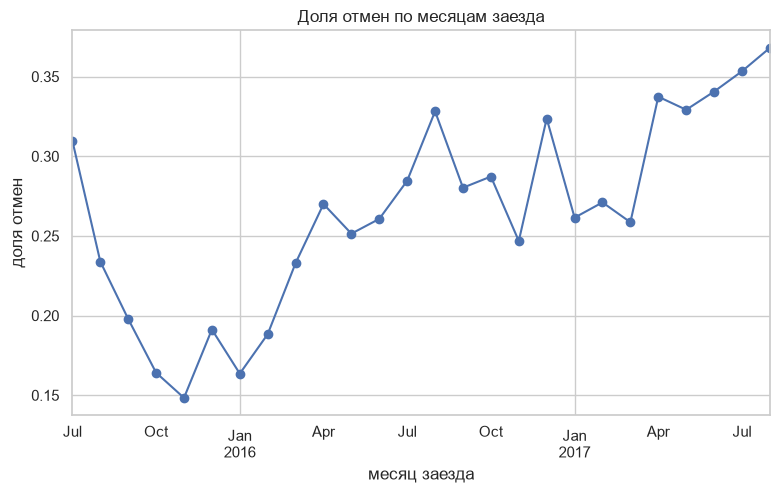

In [4]:
monthly = cancel_rates(df, df['arrival_date'].dt.to_period('M'))
fig, ax = plt.subplots()
monthly['cancel_rate'].plot(ax=ax, marker='o')
ax.set_title('Доля отмен по месяцам заезда')
ax.set_xlabel('месяц заезда')
ax.set_ylabel('доля отмен')
save_figure(fig, '01_monthly_cancel_rate')

График показывает долю отмен по месяцам заезда с июля 2015 по август 2017. После спада осенью 2015 (минимум около 15 % в ноябре) доля отмен в целом растёт и к августу 2017 доходит почти до 37 %; внутри каждого года видны летние пики.

**Вывод.** Отменяется больше четверти броней (27,7 %) и больше трети номеров (37,3 %), у городского отеля — чаще, чем у курортного. Доля отмен не постоянна: она растёт от 2015 к 2017 году и колеблется по сезонам. Поэтому на шаге 3 модель стоит проверять на более поздних данных, чем те, на которых она обучена.

## 2. Кто отменяет

**Что делаем.** Сравниваем долю отмен по сегментам продаж, каналам, типу депозита и стране гостя. Это подводит к гипотезам H2 и H5 и показывает две ловушки данных.

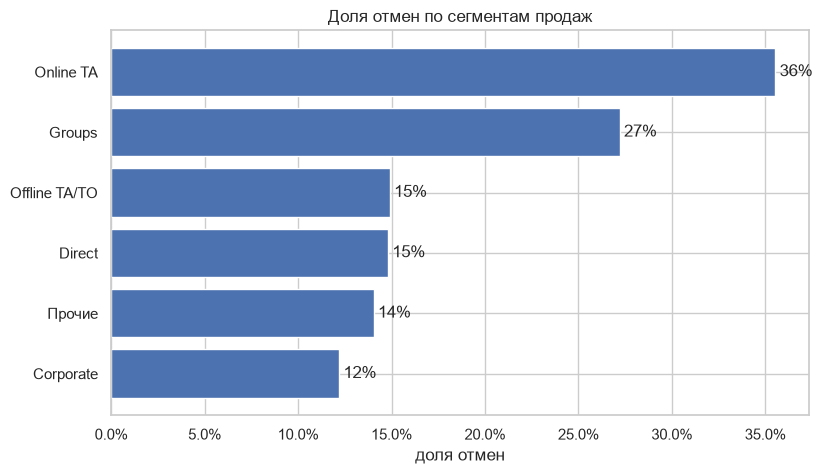

In [5]:
fig, ax = plt.subplots()
bar_rates(cancel_rates(df, segments(df)).sort_values('cancel_rate'), ax, 'Доля отмен по сегментам продаж')
save_figure(fig, '02_segments')

Столбцы — доля отменённых броней-решений по сегментам продаж (Aviation и Complementary объединены в «Прочие»). Чаще всего отменяют брони онлайн-агентств (Online TA) — 36 %, затем «Группы» — 27 %; у остальных сегментов 12–15 %, реже всего у корпоративных клиентов (12 %).

In [6]:
pd.DataFrame({
    'сырые данные (с дублями)': raw.groupby('market_segment')['is_canceled'].mean(),
    'брони-решения (шаг 1)': df.groupby('market_segment')['is_canceled'].mean(),
}).round(3).sort_values('сырые данные (с дублями)', ascending=False)

,сырые данные (с дублями),брони-решения (шаг 1)
market_segment,,
Undefined,1.000,NaN
Groups,0.611,0.272
Online TA,0.367,0.355
Offline TA/TO,0.343,0.149
Aviation,0.219,0.198
Corporate,0.187,0.122
Direct,0.153,0.148
Complementary,0.131,0.122


Это пример ловушки данных. На сырых данных «Группы» выглядят самым рискованным сегментом: 61,1 % отмен — больше, чем у онлайн-агентств (36,7 %). Но там каждый номер групповой брони — отдельная строка-дубль, и одна отмена группы считается многократно. На бронях-решениях доля отмен «Групп» — 27,2 %, это второе место после онлайн-агентств (35,5 %); так же сильно падают офлайн-агентства (34,3 % → 14,9 %), где тоже много групповых броней, а у онлайн-агентств почти ничего не меняется. Сегмент `Undefined` (2 строки) удалён на шаге 1.

In [7]:
cancel_rates(df, 'distribution_channel').round(3)

,bookings,cancel_rate,rooms,cancel_rate_rooms
distribution_channel,,,,
Corporate,5000,0.128,6583,0.222
Direct,12796,0.149,14443,0.176
GDS,178,0.202,190,0.195
TA/TO,68643,0.311,97327,0.412


По каналам продаж туроператоры и агентства (TA/TO) дают и основной объём (68 643 брони), и самую высокую долю отмен — 31,1 %. Прямые брони отменяются вдвое реже (14,9 %), корпоративные — 12,8 %; канал GDS мал (178 броней).

In [8]:
cancel_rates(df, 'deposit_type').round(3)

,bookings,cancel_rate,rooms,cancel_rate_rooms
deposit_type,,,,
No Deposit,85473,0.269,103795,0.285
Non Refund,1037,0.947,14586,0.994
Refundable,107,0.243,162,0.222


Почти все брони без депозита (85 473) отменяются в 26,9 % случаев. Аномалия — депозит «без возврата»: 1 037 броней-решений, и отменено 94,7 % из них (по номерам — 99,4 % из 14 586). Отменять бронь, за которую деньги не вернут, нелогично; похоже, это особенность учёта групповых броней. В разделе 10 проверяем, не держатся ли выводы на этих бронях.

In [9]:
top_countries = df['country'].value_counts().head(8).index
cancel_rates(df[df['country'].isin(top_countries)], 'country').sort_values('bookings', ascending=False).round(3)

,bookings,cancel_rate,rooms,cancel_rate_rooms
country,,,,
PRT,26844,0.363,47923,0.573
GBR,10399,0.191,12093,0.203
FRA,8813,0.196,10389,0.186
ESP,7228,0.257,8544,0.255
DEU,5385,0.196,7285,0.167
ITA,3056,0.351,3756,0.355
IRL,3014,0.222,3373,0.247
BEL,2078,0.197,2338,0.202


Среди восьми стран с наибольшим числом броней выделяется Португалия: 26 844 брони и 36,3 % отмен (по номерам — 57,3 %), у Италии — 35,1 %, у остальных — 19–26 %. Здесь ловушка: страну гостя часто уточняют при заезде, поэтому у тех, кто не приехал, может остаться страна по умолчанию. Значит, страна частично «подсказывает ответ», и делать по ней выводы нужно осторожно.

**Вывод.** Доля отмен сильно зависит от того, как продана бронь: онлайн-агентства (35,5 %) и «Группы» (27,2 %) против 12–15 % у прямых, корпоративных и офлайн-броней — это подводит к H2. Без склейки дублей картина была бы искажённой: «Группы» выглядели бы самым рискованным сегментом (61,1 %). Две ловушки данных — депозит «без возврата» с 94,7 % отмен и страна, которую уточняют при заезде; обе учитываем дальше.

## 3. Когда отменяют

**Что делаем.** Смотрим, как доля отмен зависит от срока брони (сколько дней от бронирования до заезда), месяца и дня недели заезда. Это подводит к гипотезе H1.

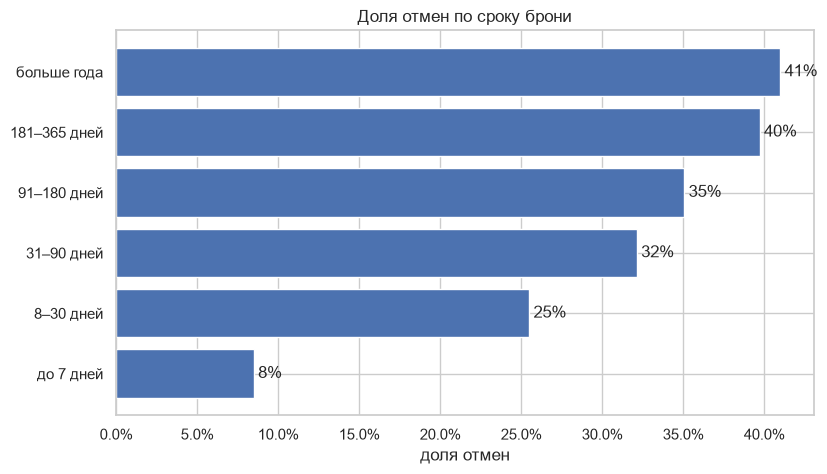

In [10]:
fig, ax = plt.subplots()
bar_rates(cancel_rates(df, lead_time_bins(df['lead_time'])), ax, 'Доля отмен по сроку брони')
save_figure(fig, '03_lead_time')

Доля отмен растёт вместе со сроком брони: 8 % у броней, сделанных за неделю до заезда, 25 % — за 8–30 дней, 32 % — за 31–90 дней, 35 % — за 91–180 дней, 40 % — за полгода–год и 41 % — больше чем за год. Рост идёт на каждом шаге, без провалов.

In [11]:
cancel_rates(df, 'arrival_month').round(3)

,bookings,cancel_rate,rooms,cancel_rate_rooms
arrival_month,,,,
1,4637,0.223,5870,0.307
2,6030,0.233,7998,0.336
3,7438,0.245,9714,0.324
4,7870,0.305,11045,0.409
5,8296,0.294,11704,0.399
6,7721,0.304,10891,0.416
7,9986,0.320,12584,0.376
8,11190,0.323,13808,0.379
9,6651,0.245,10469,0.392


По месяцам заезда доля отмен выше всего летом и весной: август — 32,3 %, июль — 32,0 %, апрель — 30,5 %. Ниже всего — в ноябре (21,4 %) и январе (22,3 %). Разброс между месяцами около 11 п. п.

In [12]:
cancel_rates(df, 'arrival_weekday').round(3)

,bookings,cancel_rate,rooms,cancel_rate_rooms
arrival_weekday,,,,
0,14042,0.269,18042,0.343
1,10874,0.246,13833,0.332
2,11155,0.257,15997,0.364
3,12878,0.279,19130,0.414
4,13226,0.307,19509,0.408
5,13026,0.302,17961,0.396
6,11416,0.267,14071,0.324


По дням недели заезда (0 — понедельник, 6 — воскресенье) разница небольшая: от 24,6 % во вторник до 30,7 % в пятницу и 30,2 % в субботу. Заезды в конце недели отменяются чуть чаще.

**Вывод.** Самый сильный «временной» сигнал — срок брони: от 8 % отмен при брони за неделю до 41 % при брони больше чем за год. Это подводит к H1. Сезон и день недели заезда тоже связаны с отменами, но слабее (разброс около 11 и 6 п. п.).

## 4. Портрет гостя

**Что делаем.** Смотрим, кто бронирует (состав, длительность, запросы, повторные визиты) и как это связано с отменами. Это подводит к гипотезам H3 и H4.

In [13]:
df[['adults', 'children', 'babies', 'nights_total', 'total_of_special_requests',
    'is_repeated_guest', 'required_car_parking_spaces']].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
adults,86617.0,1.88,0.51,0.0,2.0,2.0,2.0,10.0
children,86617.0,0.14,0.46,0.0,0.0,0.0,0.0,3.0
babies,86617.0,0.01,0.10,0.0,0.0,0.0,0.0,2.0
nights_total,86617.0,3.65,2.74,1.0,2.0,3.0,5.0,69.0
total_of_special_requests,86617.0,0.70,0.83,0.0,0.0,0.0,1.0,5.0
is_repeated_guest,86617.0,0.04,0.19,0.0,0.0,0.0,0.0,1.0
required_car_parking_spaces,86617.0,0.08,0.28,0.0,0.0,0.0,0.0,8.0


Типичная бронь — 2 взрослых (среднее 1,88) без детей, на 3 ночи (медиана; среднее 3,65, максимум — 69 ночей). Спецзапросов в среднем 0,70 на бронь, у половины броней их нет. Повторных гостей 4 %, парковки в среднем 0,08 места на бронь — её просят редко.

In [14]:
cancel_rates(df, df['total_of_special_requests'].clip(upper=3)).round(3)

,bookings,cancel_rate,rooms,cancel_rate_rooms
total_of_special_requests,,,,
0,43418,0.335,69785,0.480
1,28799,0.225,33000,0.221
2,11737,0.214,12892,0.222
3,2663,0.162,2866,0.169


Без спецзапросов отменяется 33,5 % броней, с одним запросом — 22,5 %, с двумя — 21,4 %, с тремя и больше — 16,2 %. Главный разрыв — между «нет запросов» и «есть хотя бы один» (около 11 п. п.).

In [15]:
cancel_rates(df, 'is_repeated_guest').round(3)

,bookings,cancel_rate,rooms,cancel_rate_rooms
is_repeated_guest,,,,
0,83473,0.284,115045,0.379
1,3144,0.082,3498,0.157


Повторные гости (3 144 брони) отменяют в 8,2 % случаев, новые (83 473 брони) — в 28,4 %, то есть примерно в 3,5 раза чаще.

In [16]:
cancel_rates(df, 'required_car_parking_spaces').round(3)

,bookings,cancel_rate,rooms,cancel_rate_rooms
required_car_parking_spaces,,,,
0,79328,0.302,111151,0.397
1,7256,0.000,7359,0.000
2,28,0.000,28,0.000
3,3,0.000,3,0.000
8,2,0.000,2,0.000


Среди 7 289 броней с парковкой (1, 2, 3 или 8 мест) нет ни одной отмены (0,000), без парковки — 30,2 %. Ровно ноль отмен подозрителен: похоже, парковку часто вносят в бронь при заезде. Тогда это скрытая утечка — признак отмечаем для проверки на шаге 3.

**Вывод.** Надёжнее других выглядят гости со спецзапросами (16–23 % отмен против 33,5 % без них) и повторные гости (8,2 % против 28,4 %) — это подводит к H3 и H4. Парковка показывает ровно ноль отмен — это скорее признак утечки, чем реальная закономерность, поэтому в выводы о гостях её не берём.

## 5. Деньги

**Что делаем.** Смотрим цену за ночь по месяцам в двух отелях (без бесплатных броней) и сколько стоимости бронирований приходится на отменённые брони (с учётом числа номеров). Это подводит к гипотезе H6 и даёт первую оценку потерь для расчёта экономии на шаге 4.

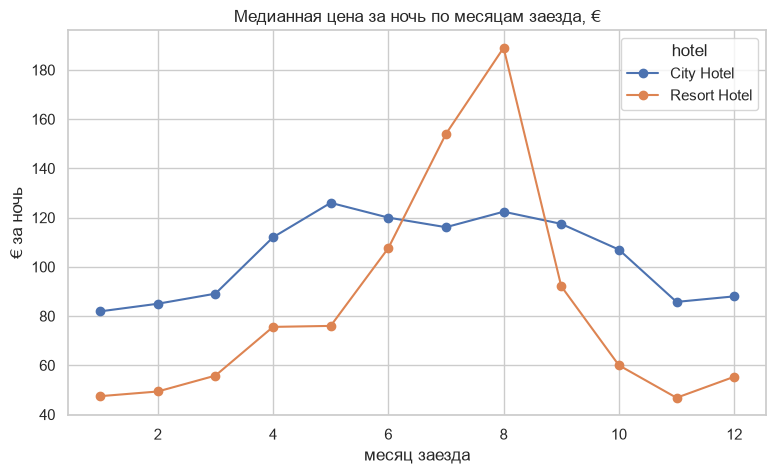

In [17]:
prices = median_price_by_month(df)
fig, ax = plt.subplots()
prices.plot(ax=ax, marker='o')
ax.set_title('Медианная цена за ночь по месяцам заезда, €')
ax.set_xlabel('месяц заезда')
ax.set_ylabel('€ за ночь')
save_figure(fig, '04_price_by_month')

Медианная цена за ночь (без бесплатных броней) у курорта меняется по сезону гораздо сильнее: от 47 € в ноябре и январе до 189 € в августе. У городского отеля — от 82 € в январе до 126 € в мае, и летом цена держится на уровне 116–122 €.

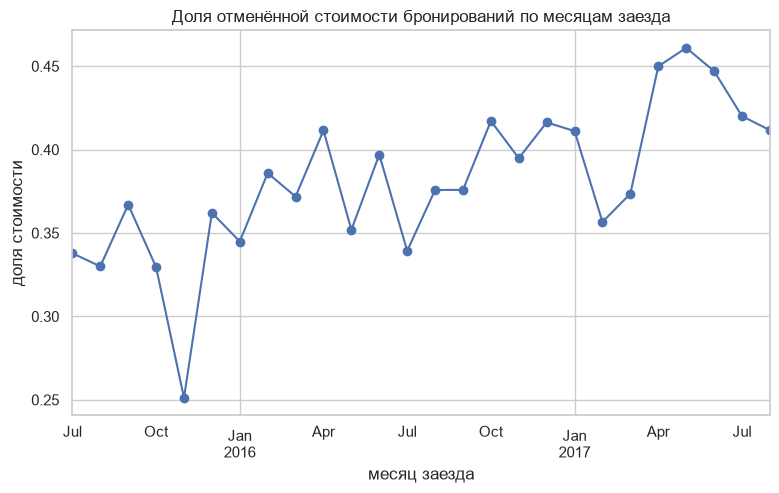

In [18]:
lost = lost_value_by_month(df)
fig, ax = plt.subplots()
lost['canceled_share'].plot(ax=ax, marker='o')
ax.set_title('Доля отменённой стоимости бронирований по месяцам заезда')
ax.set_xlabel('месяц заезда')
ax.set_ylabel('доля стоимости')
save_figure(fig, '05_lost_value')

Доля стоимости бронирований, приходящаяся на отменённые брони (с учётом числа номеров), по месяцам заезда — от 25 % (ноябрь 2015) до 46 % (май 2017). Как и доля отмен, она растёт к 2017 году.

In [19]:
pd.Series({
    'стоимость всех броней, млн €': round(lost['total_value'].sum() / 1e6, 1),
    'стоимость отменённых, млн €': round(lost['canceled_value'].sum() / 1e6, 1),
    'доля отменённой стоимости, %': round(100 * lost['canceled_value'].sum() / lost['total_value'].sum(), 1),
})

стоимость всех броней, млн €    42.7
стоимость отменённых, млн €     16.7
доля отменённой стоимости, %    39.2
dtype: float64

Всего брони стоят 42,7 млн €, из них на отменённые приходится 16,7 млн €, или 39,2 %. Это больше доли отменённых броней (27,7 %): отменяются в среднем более дорогие и крупные брони.

**Вывод.** Под угрозой отмены — 39,2 % стоимости бронирований (16,7 млн € из 42,7 млн €), это первая оценка потерь для расчёта экономии на шаге 4. Сезонность цены у курорта намного сильнее, чем у города (47–189 € против 82–126 €), — это подводит к H6: отмена летней брони курорта обходится дороже всего.

## 6. Связи числовых признаков

**Что делаем.** Строим корреляционную матрицу числовых признаков: какие признаки связаны с отменой и какие дублируют друг друга. Это пригодится при построении модели на шаге 3.

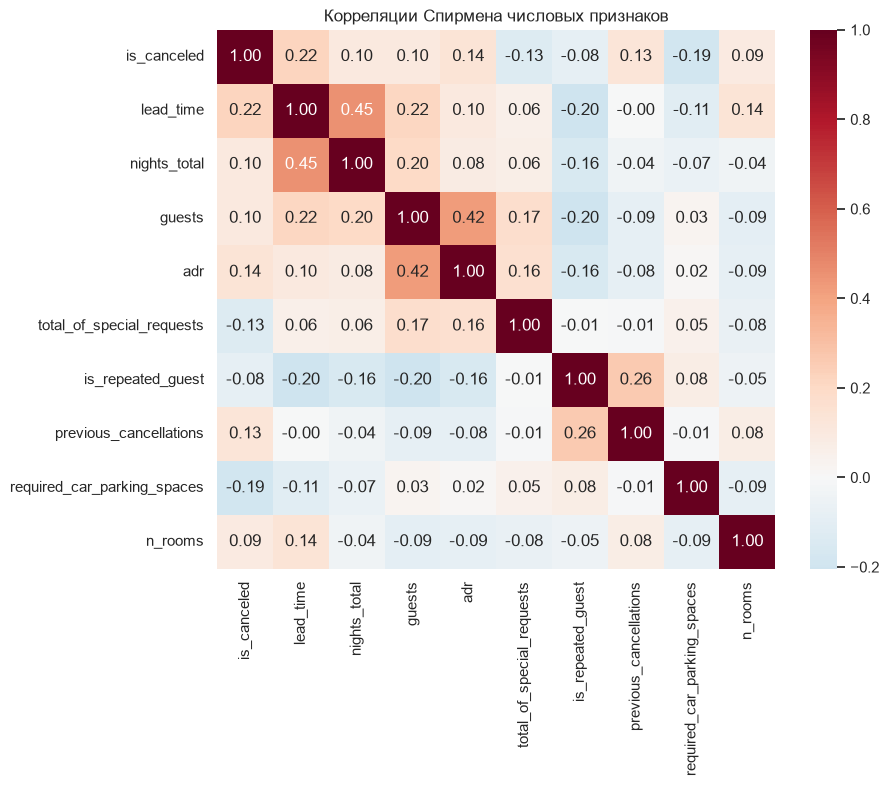

In [20]:
numeric = ['is_canceled', 'lead_time', 'nights_total', 'guests', 'adr', 'total_of_special_requests',
           'is_repeated_guest', 'previous_cancellations', 'required_car_parking_spaces', 'n_rooms']
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[numeric].corr(method='spearman'), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax)
ax.set_title('Корреляции Спирмена числовых признаков')
save_figure(fig, '06_correlations')

Матрица показывает корреляции Спирмена. С отменой сильнее всего связаны срок брони (0,22) и парковка (−0,19), затем цена (0,14), прошлые отмены (0,13) и спецзапросы (−0,13); все связи по модулю меньше 0,3. Между признаками самые сильные пары — срок брони и число ночей (0,45), число гостей и цена (0,42).

**Вывод.** Ни один числовой признак сам по себе не предсказывает отмену: все связи с ней слабые (|ρ| ≤ 0,22), значит, модели на шаге 3 нужно сочетание признаков. Сильно дублирующих друг друга признаков нет (максимум 0,45), поэтому удалять ничего не нужно.

## 7. Колонки-утечки

**Что делаем.** Разбираем, какие колонки известны в момент бронирования, а какие появляются только после заезда или отмены. Такие колонки «подсказывают ответ», и модели их давать нельзя.

In [21]:
list(LEAKAGE_COLUMNS)

['reservation_status',
 'reservation_status_date',
 'assigned_room_type',
 'booking_changes']

Это четыре колонки-утечки из шага 1: итог брони (`reservation_status`) и его дата, фактически выданный номер и число изменений брони. Их значения появляются после бронирования — при заезде, отмене или в конце проживания.

In [22]:
pd.crosstab(df['reservation_status'], df['is_canceled'])

is_canceled,0,1
reservation_status,,
Canceled,0,22969
Check-Out,62649,0
No-Show,0,999


Таблица показывает, почему `reservation_status` «подсказывает ответ»: все 22 969 броней со статусом Canceled и все 999 No-Show — отменённые (`is_canceled` = 1), а все 62 649 Check-Out — нет. Колонка повторяет целевую переменную один в один: модель с ней показала бы почти идеальную точность, но в момент брони этого статуса ещё нет.

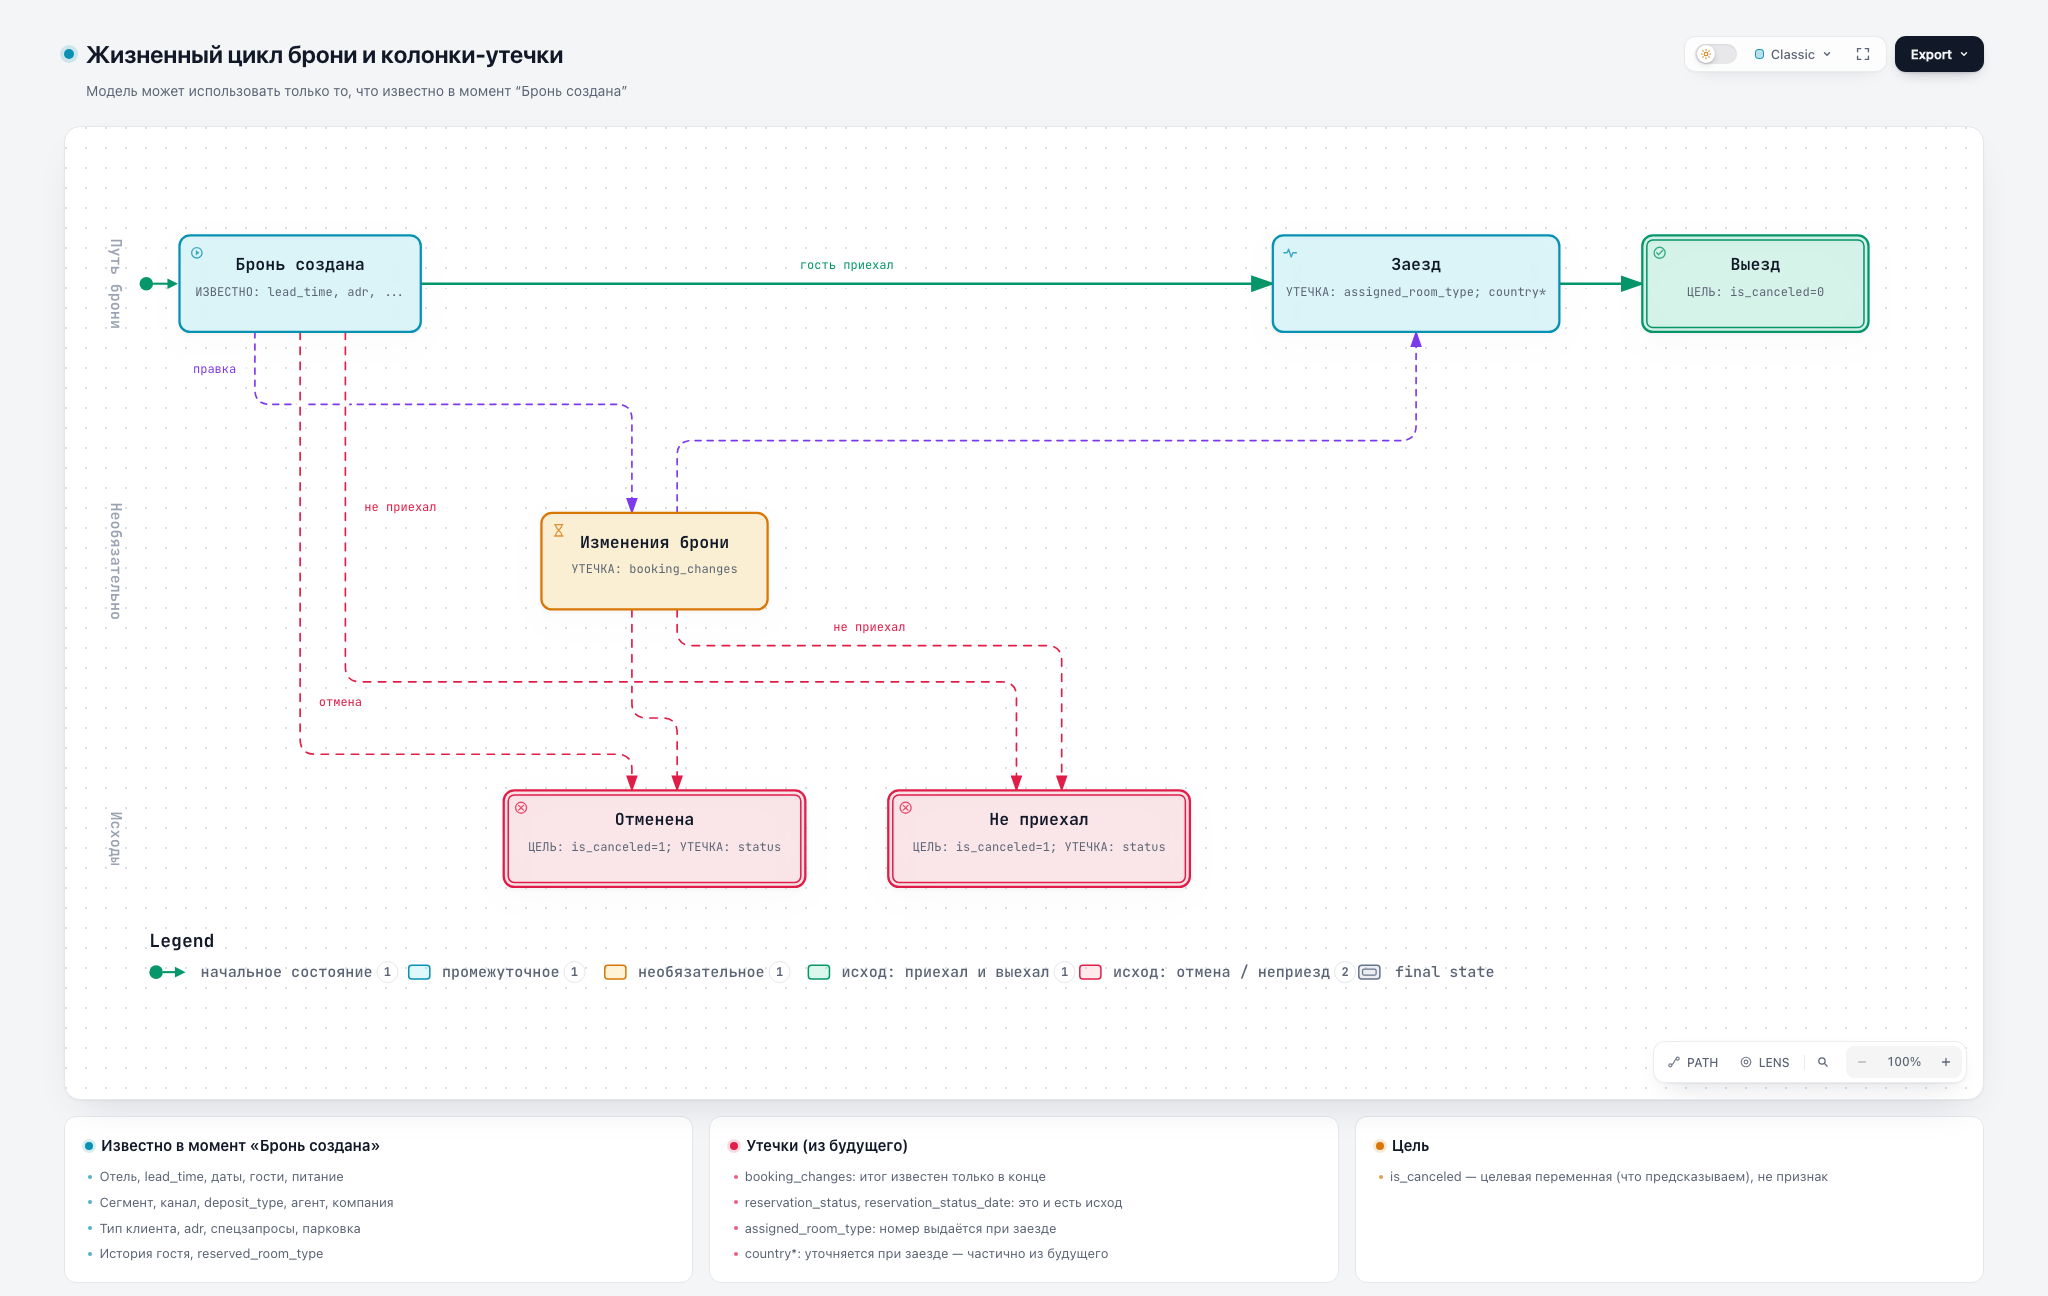

In [23]:
Image(filename=str(FIGURES_DIR / '07_booking_lifecycle.png'))

Схема показывает путь брони: «Бронь создана» → (необязательно) «Изменения брони» → один из исходов: «Отменена», «Не приехал» или «Заезд» → «Выезд». Модель может использовать только то, что известно в момент создания брони (отель, срок, даты, гости, сегмент, депозит, цена и т. д.). Утечки появляются позже: `booking_changes` — пока бронь меняют, `assigned_room_type` — при заезде, `reservation_status` и его дата — это сам исход, а страну частично уточняют при заезде. `is_canceled` — цель, то есть то, что предсказываем, а не признак.

**Вывод.** Четыре колонки-утечки исключаем из признаков модели: `reservation_status` совпадает с целью полностью (22 969 + 999 отменённых против 62 649 заездов). Страну и парковку передаём на шаг 3 как подозрительные: их частично заполняют при заезде.

## 8. Проверка гипотез

**Что делаем.** Для каждой гипотезы: формулируем H0 и H1, проверяем допущения теста, считаем p-value и **размер эффекта**. При 86 тыс. броней значимой окажется почти любая разница, поэтому важность для отеля оцениваем по размеру эффекта. Гипотез шесть, поэтому p-value поправляем методом Холма (уровень значимости 0,05). Решение «отвергаем H0» принимается, если поправленный p < 0,05 и эффект направлен так, как предсказывает гипотеза.

**Как называем размер эффекта.** V Крамера (у нас таблицы «группа × отменена или нет», одна степень свободы) и |ρ| Спирмена — по порогам Коэна (1988): меньше 0,1 — пренебрежимо малый, 0,1–0,3 — слабый, 0,3–0,5 — умеренный, от 0,5 — сильный. ε² Краскела — Уоллиса — по Томчак и Томчак (2014): от 0,01 — слабый, от 0,08 — умеренный, от 0,26 — сильный. Разницу долей отмен даём в процентных пунктах (п. п.) и оцениваем практически, относительно средней доли отмен 27,7 %: до 5 п. п. — малая, 5–15 п. п. — заметная, больше 15 п. п. — большая (это наша рабочая шкала для отеля, а не общепринятый стандарт).

In [24]:
table = hypotheses_table(df)

Считаем все шесть тестов сразу — поправка Холма учитывает их вместе. Ниже разбираем каждую гипотезу.

### H1

**Что проверяем.** Чем раньше бронируют, тем чаще отменяют.

**Что это даст отелю.** ранние брони — кандидаты на предоплату.

**H0:** доля отмен не зависит от срока брони  
**H1:** доля отмен различается по корзинам срока брони и растёт со сроком

In [25]:
min_expected_count(lead_time_bins(df['lead_time']), df['is_canceled'])

155.23566967223525

Допущение χ²: в каждой ячейке таблицы «корзина срока × отменена или нет» ожидаемое число броней не меньше 5. Минимальное ожидаемое — 155, допущение выполнено.

In [26]:
h1_trend(df)

StatResult(test='корреляция Спирмена', statistic=0.22436225408486768, p_value=0.0, effect_name='ρ Спирмена', effect=0.22436225408486768, ci_low=nan, ci_high=nan)

Корреляция Спирмена между сроком брони в днях и отменой — ρ = 0,22 (p < 0,001; в выводе p округлён до 0). Знак положительный: чем больше срок брони, тем чаще отмена. Именно ρ показывает направление связи, которого χ² не даёт.

In [27]:
table.set_index('hypothesis').loc['H1']

statement      Чем раньше бронируют, тем чаще отменяют
test                                  χ² независимости
statistic                                  4900.348822
p_value                                            0.0
effect_name                                  V Крамера
effect                                        0.237855
ci_low                                             NaN
ci_high                                            NaN
p_holm                                             0.0
reject_h0                                         True
Name: H1, dtype: object

χ² независимости по шести корзинам срока брони: статистика 4 900, p < 0,001 (и после поправки Холма), V Крамера = 0,24.

**Решение.** Отвергаем H0 (p с поправкой Холма < 0,001). χ² и V Крамера = 0,24 показывают только, что доля отмен различается по корзинам срока брони; направление «чем раньше, тем чаще» подтверждают положительный ρ Спирмена = 0,22 и рост доли отмен в каждой следующей корзине — от 8,5 % (до 7 дней) до 41 % (больше года). По Коэну связь слабая (0,24 и 0,22), но практически разница большая: ранние брони отменяются в 4–5 раз чаще поздних. Для отеля это главный кандидат на условие предоплаты; это связь, а не причина — сам срок брони не заставляет отменять.

### H2

**Что проверяем.** Сегменты продаж различаются по доле отмен.

**Что это даст отелю.** каким каналам ужесточить условия.

**H0:** доля отмен одинакова во всех сегментах  
**H1:** хотя бы в одном сегменте доля отмен другая

In [28]:
min_expected_count(segments(df), df['is_canceled'])

250.1480309869887

Допущение χ² по шести сегментам (Aviation и Complementary объединены в «Прочие»): минимальное ожидаемое число в ячейке — 250, больше 5, допущение выполнено.

In [29]:
h2_pairwise(df).round(4)

,segment_a,segment_b,diff,p_value,p_holm
0,Corporate,Direct,-0.0261,0.0000,0.0002
1,Corporate,Groups,-0.1501,0.0000,0.0000
2,Corporate,Offline TA/TO,-0.0271,0.0000,0.0001
3,Corporate,Online TA,-0.2334,0.0000,0.0000
4,Corporate,Прочие,-0.0184,0.1292,0.5170
5,Direct,Groups,-0.1240,0.0000,0.0000
6,Direct,Offline TA/TO,-0.0009,0.8326,1.0000
7,Direct,Online TA,-0.2073,0.0000,0.0000
8,Direct,Прочие,0.0077,0.5311,1.0000
9,Groups,Offline TA/TO,0.1230,0.0000,0.0000


Попарные z-тесты (15 пар, поправка Холма внутри H2; `diff` — доля отмен первого сегмента минус второго). Онлайн-агентства отменяют чаще всех остальных сегментов (на 8,3–23,3 п. п.), «Группы» — чаще всех, кроме онлайн-агентств (на 12,3–15,0 п. п.). Прямые, офлайн-агентства и «Прочие» между собой не различаются (p с поправкой = 1,00); корпоративные отменяют реже прямых и офлайн-агентств на 2,6–2,7 п. п., а от «Прочих» значимо не отличаются (p = 0,52).

In [30]:
table.set_index('hypothesis').loc['H2']

statement      Сегменты продаж различаются по доле отмен
test                                    χ² независимости
statistic                                    4249.146187
p_value                                              0.0
effect_name                                    V Крамера
effect                                          0.221488
ci_low                                               NaN
ci_high                                              NaN
p_holm                                               0.0
reject_h0                                           True
Name: H2, dtype: object

χ² по сегментам: статистика 4 249, p < 0,001, V Крамера = 0,22.

**Решение.** Отвергаем H0 (p с поправкой Холма < 0,001): сегменты различаются по доле отмен. V Крамера = 0,22 говорит только о том, что различия есть (по Коэну — слабая связь); какие именно — видно из попарной таблицы. Сегменты делятся на три уровня: онлайн-агентства (35,5 %), «Группы» (27,2 %) и остальные (12–15 %). Разница между онлайн-агентствами и прямыми бронями — 20,7 п. п., это большая разница для отеля: условия бронирования через онлайн-агентства стоит ужесточать в первую очередь. Это связь, а не причина: через разные каналы бронируют разные гости.

### H3

**Что проверяем.** Гости со спецзапросами отменяют реже.

**Что это даст отелю.** надёжным гостям можно не брать предоплату.

**H0:** доля отмен со спецзапросами и без них одинакова  
**H1:** со спецзапросами доля отмен ниже

In [31]:
(df['total_of_special_requests'] >= 1).value_counts()

total_of_special_requests
False    43418
True     43199
Name: count, dtype: int64

Группы для сравнения почти равны: 43 418 броней без спецзапросов и 43 199 — хотя бы с одним. Обе группы большие, z-тест для двух долей применим.

In [32]:
table.set_index('hypothesis').loc['H3']

statement      Гости со спецзапросами отменяют реже
test                          z-тест для двух долей
statistic                                -38.289628
p_value                                         0.0
effect_name                           разница долей
effect                                    -0.116407
ci_low                                    -0.122313
ci_high                                   -0.110501
p_holm                                          0.0
reject_h0                                      True
Name: H3, dtype: object

z = −38,3, p < 0,001. Доля отмен со спецзапросами ниже на 11,6 п. п. (95 % ДИ — от 11,1 до 12,2 п. п.).

**Решение.** Отвергаем H0 (p с поправкой Холма < 0,001): гости со спецзапросами отменяют реже — 21,9 % против 33,5 % без запросов. Разница 11,6 п. п. по нашей шкале заметная: примерно на треть меньше отмен. Для отеля это сигнал, что бронь со спецзапросом надёжнее и предоплату с неё можно не брать. Это связь, а не причина: запрос — признак серьёзных планов, а не то, что удерживает гостя.

### H4

**Что проверяем.** Повторные гости отменяют реже.

**Что это даст отелю.** постоянным гостям можно смягчить условия.

**H0:** доля отмен у повторных и новых гостей одинакова  
**H1:** у повторных гостей доля отмен ниже

In [33]:
df['is_repeated_guest'].value_counts()

is_repeated_guest
0    83473
1     3144
Name: count, dtype: int64

Повторных гостей мало — 3 144 брони против 83 473 у новых, но для z-теста этого хватает — в обеих группах достаточно отмен: даже у повторных гостей их около 260 (8,2 % от 3 144).

In [34]:
table.set_index('hypothesis').loc['H4']

statement      Повторные гости отменяют реже
test                   z-тест для двух долей
statistic                         -24.811167
p_value                                  0.0
effect_name                    разница долей
effect                             -0.201653
ci_low                             -0.211738
ci_high                            -0.191567
p_holm                                   0.0
reject_h0                               True
Name: H4, dtype: object

z = −24,8, p < 0,001. Доля отмен у повторных гостей ниже на 20,2 п. п. (95 % ДИ — от 19,2 до 21,2 п. п.).

**Решение.** Отвергаем H0 (p с поправкой Холма < 0,001): повторные гости отменяют в 8,2 % случаев против 28,4 % у новых. Разница 20,2 п. п. — большая, самый сильный эффект среди H3–H5. Постоянным гостям можно смягчить условия предоплаты, но их всего 4 % броней, поэтому на общие потери это влияет мало. Это связь, а не причина.

### H5

**Что проверяем.** Городской отель теряет на отменах больше курортного.

**Что это даст отелю.** разные правила предоплаты для двух отелей.

**H0:** доля отмен в двух отелях одинакова  
**H1:** в городском отеле доля отмен выше

In [35]:
cancel_rates(df, 'hotel')[['bookings', 'cancel_rate', 'cancel_rate_rooms']].round(3)

,bookings,cancel_rate,cancel_rate_rooms
hotel,,,
City Hotel,53036,0.302,0.419
Resort Hotel,33581,0.237,0.280


Городской отель отменяется чаще: 30,2 % броней против 23,7 % у курортного; по номерам — 41,9 % против 28,0 %.

In [36]:
canceled_value = df['booking_value'].where(df['is_canceled'] == 1, 0)
(canceled_value.groupby(df['hotel']).sum() / df.groupby('hotel')['booking_value'].sum()).round(3)

hotel
City Hotel      0.431
Resort Hotel    0.335
Name: booking_value, dtype: float64

Доля отменённой стоимости бронирований (с учётом числа номеров): у городского отеля 43,1 %, у курортного — 33,5 %. Именно этот показатель отвечает на вопрос «кто теряет больше».

In [37]:
table.set_index('hypothesis').loc['H5']

statement      Городской отель теряет на отменах больше курортного
test                                         z-тест для двух долей
statistic                                                20.908311
p_value                                                        0.0
effect_name                                          разница долей
effect                                                    0.065232
ci_low                                                    0.059237
ci_high                                                   0.071227
p_holm                                                         0.0
reject_h0                                                     True
Name: H5, dtype: object

z = 20,9, p < 0,001. Доля отмен у городского отеля выше на 6,5 п. п. (95 % ДИ — от 5,9 до 7,1 п. п.).

**Решение.** Отвергаем H0 (p с поправкой Холма < 0,001): городской отель отменяется чаще на 6,5 п. п., и доля отменённой стоимости у него выше (43,1 % против 33,5 %). По нашей шкале разница заметная, но на нижней границе: она меньше, чем у сегментов или срока брони. Разные правила для двух отелей оправданы, но главное различие между бронями — не в отеле, а в канале и сроке. Это связь, а не причина: в отелях разный состав гостей и каналов.

### H6

**Что проверяем.** Цена у курорта сильнее зависит от сезона, чем у города.

**Что это даст отелю.** когда отмена дороже всего.

**H0:** распределение цены одинаково во всех месяцах (в каждом отеле)  
**H1:** цена различается по месяцам, и у курорта эффект сезона сильнее

In [38]:
pd.DataFrame({hotel: vars(res) for hotel, res in h6_by_hotel(df).items()}).T

,test,statistic,p_value,effect_name,effect,ci_low,ci_high
City Hotel,Краскел — Уоллис,9638.452803,0.0,ε²,0.184246,NaN,NaN
Resort Hotel,Краскел — Уоллис,20086.390185,0.0,ε²,0.603884,NaN,NaN


Краскел — Уоллис по месяцам заезда (без бесплатных броней) в каждом отеле: в обоих p < 0,001. ε² у городского отеля 0,18 (умеренный эффект), у курортного — 0,60 (сильный): месяц объясняет гораздо большую часть разброса цены курорта.

In [39]:
prices.agg(['min', 'max']).T.assign(отношение=lambda t: (t['max'] / t['min']).round(2))

,min,max,отношение
hotel,,,
City Hotel,81.9,126.0,1.54
Resort Hotel,46.8,189.0,4.04


Медианная цена по месяцам у городского отеля меняется от 81,9 до 126,0 € (в 1,54 раза), у курортного — от 46,8 до 189,0 € (в 4,04 раза).

In [40]:
table.set_index('hypothesis').loc['H6']

statement      Цена у курорта сильнее зависит от сезона, чем у города
test                                                 Краскел — Уоллис
statistic                                                20086.390185
p_value                                                           0.0
effect_name                                      ε² курорт − ε² город
effect                                                       0.419638
ci_low                                                            NaN
ci_high                                                           NaN
p_holm                                                            0.0
reject_h0                                                        True
Name: H6, dtype: object

В сводной таблице для H6: статистика — H курорта, p — наибольший из двух отелей, эффект — разница ε² курорта и города, 0,42.

**Решение.** Отвергаем H0 (p с поправкой Холма < 0,001): цена значимо различается по месяцам в каждом отеле. Вывод «у курорта сезонность сильнее» — описательное сравнение размеров эффекта (ε² 0,60 против 0,18; размах медиан в 4,04 раза против 1,54), а не отдельный тест на разницу между отелями. Разница очень большая, поэтому вывод надёжен по смыслу. Для отеля: отмена летней брони курорта стоит дороже всего, предоплата там важнее. Это связь, а не причина.

## 9. Сводная таблица гипотез

**Что делаем.** Собираем результаты всех шести проверок в одну таблицу: тест, размер эффекта, p-value до и после поправки Холма, решение.

In [41]:
table[['hypothesis', 'statement', 'test', 'effect_name', 'effect', 'ci_low', 'ci_high',
       'p_value', 'p_holm', 'reject_h0']].round(4)

,hypothesis,statement,test,effect_name,effect,ci_low,ci_high,p_value,p_holm,reject_h0
0,H1,"Чем раньше бронируют, тем чаще отменяют",χ² независимости,V Крамера,0.2379,NaN,NaN,0.0,0.0,True
1,H2,Сегменты продаж различаются по доле отмен,χ² независимости,V Крамера,0.2215,NaN,NaN,0.0,0.0,True
2,H3,Гости со спецзапросами отменяют реже,z-тест для двух долей,разница долей,-0.1164,-0.1223,-0.1105,0.0,0.0,True
3,H4,Повторные гости отменяют реже,z-тест для двух долей,разница долей,-0.2017,-0.2117,-0.1916,0.0,0.0,True
4,H5,Городской отель теряет на отменах больше курортного,z-тест для двух долей,разница долей,0.0652,0.0592,0.0712,0.0,0.0,True
5,H6,"Цена у курорта сильнее зависит от сезона, чем у города",Краскел — Уоллис,ε² курорт − ε² город,0.4196,NaN,NaN,0.0,0.0,True


Все шесть гипотез отвергают H0 после поправки Холма (p_holm < 0,001; в таблице округлено до 0), и эффект везде в ожидаемую сторону. Размеры эффекта: V Крамера 0,24 (H1) и 0,22 (H2); разницы долей −11,6 п. п. (H3), −20,2 п. п. (H4), +6,5 п. п. (H5); разница ε² 0,42 (H6). У разниц долей 95 % ДИ не содержат 0.

**Вывод.** Все шесть гипотез подтверждаются, но по силе они разные. Практически важнее всего срок брони (8,5 % → 41 %), сегмент продаж (онлайн-агентства 35,5 % против 12–15 %), повторные гости (−20,2 п. п.) и сезонность цены курорта; разница между отелями (+6,5 п. п.) — самая небольшая из подтверждённых.

## 10. Устойчивость выводов

**Что делаем.** Повторяем все шесть проверок на других вариантах данных: A — дубли удалены, B — дубли оставлены, и C без броней с депозитом «без возврата» (аномалия: 95 % отмен). Вывод считаем устойчивым, если решение по гипотезе одинаково во всех вариантах.

In [42]:
decisions = robustness(raw)
save_hypotheses(table, decisions)
decisions

,C,A,B,C без Non Refund,robust
hypothesis,,,,,
H1,True,True,True,True,True
H2,True,True,True,True,True
H3,True,True,True,True,True
H4,True,True,True,True,True
H5,True,True,True,True,True
H6,True,True,True,True,True


Во всех четырёх вариантах — C (основной), A (дубли удалены), B (дубли оставлены) и C без 1 037 броней «без возврата» — решения по всем шести гипотезам одинаковые (True), колонка `robust` — True везде. Таблица вместе с отметкой устойчивости сохранена в `reports/hypotheses.csv`.

**Вывод.** Все выводы устойчивы. Это важно по двум причинам. Во-первых, способ обработки дублей (раздел 4 шага 1) заметно меняет картину — на сырых данных «Группы» отменяют 61,1 % против 27,2 % на бронях-решениях, — но ни одно решение по гипотезам от него не зависит. Во-вторых, аномальные брони «без возврата» (94,7 % отмен) не создают ни одного вывода: без них решения те же.

## 11. Выводы шага

1. **Подтвердились все шесть гипотез** (p с поправкой Холма < 0,001, эффект в ожидаемую сторону), но сила разная. Самые важные для отеля — срок брони (H1: 8,5 % отмен при брони за неделю против 41 % — больше чем за год), канал продаж (H2: онлайн-агентства 35,5 % против 12–15 % у прямых и корпоративных) и повторные гости (H4: 8,2 % против 28,4 %). Спецзапросы (H3) снижают долю отмен на 11,6 п. п., городской отель отменяется чаще курортного на 6,5 п. п. (H5). Везде это **связь, а не причина**.
2. **С кого брать предоплату.** Кандидаты — ранние брони и брони через онлайн-агентства: у них доля отмен в 2–5 раз выше, чем у поздних и прямых броней. Под угрозой отмены — 39,2 % стоимости бронирований (16,7 млн € из 42,7 млн €).
3. **С кого не брать.** Повторные гости и гости со спецзапросами отменяют заметно реже; им можно оставить мягкие условия. Повторных гостей всего 4 % броней, поэтому большой экономии это не даст, но и риск невелик.
4. **Разные правила для двух отелей и где отмена дороже.** Городской отель теряет больше (43,1 % стоимости против 33,5 %), но разница между отелями меньше, чем между каналами и сроками брони. Цена у курорта сильно зависит от сезона (медиана 47–189 €, ε² 0,60 против 0,18 у города) — летняя отмена на курорте обходится дороже всего; это описательное сравнение, а не отдельный тест.
5. **Устойчивость.** Решения по всем гипотезам одинаковы на вариантах A, B, C и без броней «без возврата». Обработка дублей важна для описания данных — на сырых данных «Группы» выглядели самым рискованным сегментом (61,1 % отмен вместо 27,2 %), — но выводы по гипотезам от неё не зависят.
6. **Ограничения.** Два отеля в Португалии, заезды 07.2015–08.2017; данные наблюдательные, поэтому говорим о связях, а не о причинах. Склейка одинаковых строк в групповые брони — обоснованное предположение (шаг 1), а не известный факт. Доля отмен растёт от 2015 к 2017 году, поэтому результаты могут меняться во времени.
7. **Что передаём на шаг 3.** Признаки-кандидаты: срок брони, сегмент и канал продаж, спецзапросы, повторный гость, отель, месяц заезда, цена, прошлые отмены. Исключаем утечки: `reservation_status` (и его дату), `assigned_room_type`, `booking_changes`. С осторожностью — страна и парковка: их частично заполняют при заезде (у броней с парковкой ровно 0 % отмен). Модель проверяем на более поздних данных, чем обучающие.